# StyleMatch — a guided walkthrough

**Question:** if we know which clothing products a person liked in the past, which 10 products should we show them next?

This notebook rebuilds the whole StyleMatch experiment from scratch, one small step at a time, and explains every term the first time it appears. It uses the same data, split, models, metrics and random seed as `scripts/benchmark.py`, so at the end the numbers match `results/metrics.csv`.

**How to read it**

1. **Glossary** — plain-language definitions of every term used.
2. **Steps 1–5** — load data, split by time, build the user×product matrix, choose who to evaluate.
3. **Step 6** — the evaluation metrics, worked out by hand on a tiny example.
4. **Step 7** — the five models, each first on a toy example you can verify by eye, then on the real data.
5. **Steps 8–11** — pick the blend weight, run the test, compare, quantify uncertainty.
6. **Step 12** — what the results do and don't tell us.

Run the cells top to bottom. Nothing here writes to `data/` or `results/`; the notebook only reads them.

## Glossary

### The problem and the data

| Term | Meaning |
|---|---|
| **Recommender system** | Software that ranks items (here: fashion products) for a person so the most relevant ones are shown first. |
| **User / item** | A *user* is a reviewer (`reviewerID`); an *item* is a product (`asin`, Amazon's product code). |
| **Interaction** | One user–item pair with some evidence of interest, here "user reviewed item". |
| **Explicit feedback** | Direct opinions, such as a 1–5 star rating. |
| **Implicit feedback** | Behaviour that *suggests* interest without asking, such as a click or a purchase. We turn stars into implicit feedback: a rating of **4 or 5 = "liked" (1)**, anything else is not counted as a positive. |
| **Interaction matrix** | A table with one row per user and one column per item; cell = 1 if the user liked the item, else 0. |
| **Sparse / sparsity** | Almost every cell is 0 (nobody has seen most products). We store only the non-zero cells (**CSR format**, "compressed sparse row") to save memory. |
| **5-core** | A pre-filter in this dataset: every user and every item has at least 5 reviews. It removes the very sparsest users/items. |
| **Catalog / candidate set** | The items that are allowed to be recommended. Here: every item that has at least one positive in the training data. |
| **Warm vs cold** | A *warm* user/item appears in training; a *cold* (new) one does not. Recommending for cold ones is the **cold-start problem**; this experiment deliberately excludes it. |
| **Unix timestamp** | Seconds since 1 Jan 1970 UTC. Used to order reviews in time. |

### Splitting and fairness

| Term | Meaning |
|---|---|
| **Training set** | The oldest data. Models learn from it. |
| **Validation set** | The middle slice. Used to *choose settings* (here, the blend weight). |
| **Test set** | The newest slice. Used **once** at the end to report honest performance. |
| **Chronological (temporal) split** | Split by time: train on the past, test on the future. This mimics real use, where you recommend today using only yesterday's data. |
| **Data leakage** | Information from the test period accidentally reaching the model during training or tuning, which inflates scores. A random split would leak (it could train on a review written *after* the one it predicts). |
| **Hyperparameter** | A setting chosen by the experimenter rather than learned from data (neighbours = 100, components = 64, blend weight). |
| **Seed** | The starting value of a random number generator. A fixed seed (42) makes "random" choices repeatable. |

### Models

| Term | Meaning |
|---|---|
| **Baseline** | A simple reference method. A fancy model is only interesting if it beats these. |
| **Random** | Scores items with random numbers. The floor: any real model must beat it. |
| **Popularity** | Recommends the items liked by the most users, the same list for everybody. Surprisingly hard to beat. |
| **Collaborative filtering (CF)** | Recommend using *other people's behaviour* ("people who liked what you liked also liked…"), without looking at what the product is. |
| **ItemKNN** | "Item-based k-nearest-neighbours" CF. Two items are *similar* if many of the same users liked both. Score an item by its similarity to what you already liked. |
| **Cosine similarity** | Similarity of two vectors as the cosine of the angle between them: 1 = same direction (liked by the same users), 0 = nothing in common. |
| **Matrix factorization** | Approximate the big user×item matrix by multiplying two thin matrices: one describing users, one describing items. |
| **Latent factors** | The hidden "taste dimensions" that factorization discovers (nobody names them, e.g. "sporty vs formal"). Each user and item becomes a short list of numbers, one per factor. |
| **SVD / truncated SVD** | *Singular Value Decomposition* is one way to do matrix factorization. *Truncated* means we keep only the strongest **64 components** (factors) and drop the rest. It factorizes the 0/1 "liked" matrix and does not predict star ratings. |
| **Blend / hybrid** | A weighted mix of two scorers: `weight × ItemKNN + (1 − weight) × Popularity`. |

### Evaluation

| Term | Meaning |
|---|---|
| **Top-K list (K = 10)** | The 10 highest-scored items for a user: what would actually be shown. |
| **Relevant / held-out items** | Items the user liked in the *test* period. The model never saw them; we check whether it ranks them highly. |
| **Hit** | A recommended item that is relevant. |
| **Precision@10** | Hits ÷ 10. "Of what I showed, how much was right?" |
| **Recall@10** | Hits ÷ number of relevant items. "Of what they liked, how much did I find?" |
| **NDCG@10** | *Normalized Discounted Cumulative Gain.* Rewards hits, but hits near the top of the list count more (a discount of 1/log₂(rank+1)). Divided by the best possible score so it lies between 0 and 1. **Our main metric.** |
| **MRR@10** | *Mean Reciprocal Rank.* 1 ÷ position of the first hit (1, ½, ⅓, …), or 0 if none. "How soon did the first good item appear?" |
| **Catalog coverage** | Share of the whole catalog that was recommended to *anyone*. Low coverage = the same few items for everybody. Not an accuracy measure. |
| **Macro-average** | Compute each metric per user, then average over users, so every user counts equally. |
| **Bootstrap** | Resample the users with replacement thousands of times to see how much an average would wobble by chance. |
| **Paired comparison** | Compare two models *on the same users* and average the per-user difference. |
| **95% confidence interval (CI)** | The range containing the middle 95% of the bootstrap results. If it includes 0, we cannot claim a real difference. |
| **Fit seconds** | Time to prepare (train) the model. |

## Setup

In [1]:
import gzip
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, diags
from sklearn.decomposition import TruncatedSVD

SEED = 42   # fixed seed so every "random" step is repeatable
K = 10      # we evaluate the top-10 list

# Find the project root whether Jupyter was started in the root or in notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data/raw/reviews_Clothing_Shoes_and_Jewelry_5.json.gz'
assert RAW.exists(), f'Run scripts/download_data.py first ({RAW} missing)'

pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda v: f'{v:.5f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## Step 1 — Load the reviews

The file is *JSON Lines*: one JSON object (one review) per line, gzip-compressed. Let's look at one raw record first.

In [2]:
with gzip.open(RAW, 'rt') as stream:
    first = json.loads(next(stream))
print(json.dumps(first, indent=2)[:900])

{
  "reviewerID": "A1KLRMWW2FWPL4",
  "asin": "0000031887",
  "reviewerName": "Amazon Customer \"cameramom\"",
  "helpful": [
    0,
    0
  ],
  "reviewText": "This is a great tutu and at a really great price. It doesn't look cheap at all. I'm so glad I looked on Amazon and found such an affordable tutu that isn't made poorly. A++",
  "overall": 5.0,
  "summary": "Great tutu-  not cheaply made",
  "unixReviewTime": 1297468800,
  "reviewTime": "02 12, 2011"
}


We only need four of those fields:

* `reviewerID` → **user_id**
* `asin` → **item_id** (the product)
* `overall` → **rating** (1–5 stars)
* `unixReviewTime` → **timestamp**

The review *text* is deliberately ignored: this experiment uses behaviour only.

In [3]:
rows = []
with gzip.open(RAW, 'rt') as stream:
    for line in stream:
        record = json.loads(line)
        rows.append((record['reviewerID'], record['asin'], record['overall'], record['unixReviewTime']))

data = pd.DataFrame(rows, columns=['user_id', 'item_id', 'rating', 'timestamp'])
raw_count = len(data)
print(f'{raw_count:,} reviews | {data.user_id.nunique():,} users | {data.item_id.nunique():,} products')
data.head()

278,677 reviews | 39,387 users | 23,033 products


,user_id,item_id,rating,timestamp
0,A1KLRMWW2FWPL4,0000031887,5.00000,1297468800
1,A2G5TCU2WDFZ65,0000031887,5.00000,1358553600
2,A1RLQXYNCMWRWN,0000031887,5.00000,1357257600
3,A8U3FAMSJVHS5,0000031887,5.00000,1398556800
4,A3GEOILWLK86XM,0000031887,5.00000,1394841600


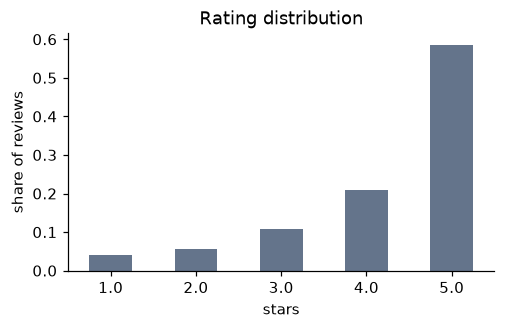

Share of reviews rated 4 or 5: 79.5%


In [4]:
# How are star ratings distributed? Most reviews are positive, which matters for the 'liked = 4 or 5' rule.
share = data.rating.value_counts(normalize=True).sort_index()
ax = share.plot.bar(color='#64748b', figsize=(5, 2.8), rot=0)
ax.set_xlabel('stars'); ax.set_ylabel('share of reviews'); ax.set_title('Rating distribution')
plt.show()
print(f'Share of reviews rated 4 or 5: {share.loc[[4.0, 5.0]].sum():.1%}')

## Step 2 — Clean and split by time

**Deduplicate.** If a user reviewed the same product twice we keep only the *earliest* review, so each user–item pair appears once. Sorting by timestamp (then user, item, to break ties deterministically) before `drop_duplicates(keep='first')` does this.

**Split chronologically so that about 80% / 10% / 10% of the *reviews* land in train / validation / test.**
The cut dates are the 80th and 90th percentile of the review timestamps: everything before the first date is *train*, between the two dates is *validation*, and after the second is *test*. Using a date boundary (`<` / `>=`) keeps reviews written on the same day in the same partition.

In [5]:
data = (data.sort_values(['timestamp', 'user_id', 'item_id'])
            .drop_duplicates(['user_id', 'item_id'], keep='first'))
print(f'{raw_count:,} raw reviews -> {len(data):,} unique user-item pairs')

# Timestamps at the 80th and 90th percentile = the two cut dates.
train_cut, test_cut = [int(data.timestamp.quantile(q)) for q in (0.8, 0.9)]

train      = data[data.timestamp <  train_cut].copy()
validation = data[(data.timestamp >= train_cut) & (data.timestamp < test_cut)].copy()
test       = data[data.timestamp >= test_cut].copy()

# Safety checks: strict temporal ordering means no leakage between partitions.
assert train.timestamp.max() < validation.timestamp.min()
assert validation.timestamp.max() < test.timestamp.min()

as_date = lambda t: pd.to_datetime(t, unit='s', utc=True).date()
summary = pd.DataFrame({
    'rows': [len(train), len(validation), len(test)],
    'from': [as_date(train.timestamp.min()), as_date(validation.timestamp.min()), as_date(test.timestamp.min())],
    'to':   [as_date(train.timestamp.max()), as_date(validation.timestamp.max()), as_date(test.timestamp.max())],
}, index=['train', 'validation', 'test'])
summary

278,677 raw reviews -> 278,677 unique user-item pairs


,rows,from,to
train,222413,2003-03-29,2014-03-19
validation,28185,2014-03-20,2014-05-17
test,28079,2014-05-18,2014-07-23


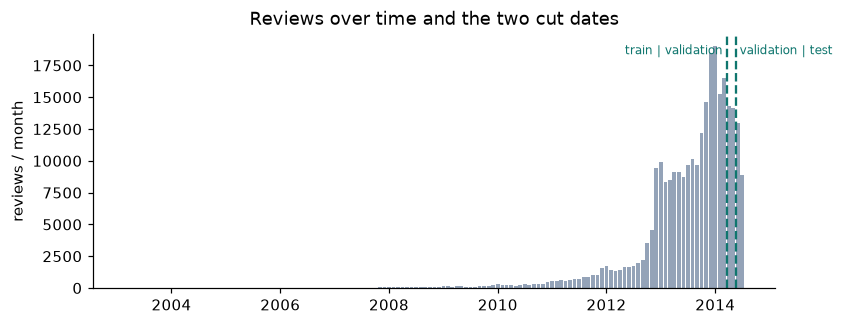

In [6]:
# Visualise the split: reviews per month, with the two cut dates marked.
months = pd.to_datetime(data.timestamp, unit='s').dt.to_period('M').value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(months.index.to_timestamp(), months.values, width=25, color='#94a3b8')
# The two cuts are only ~2 months apart, so put one label on each side to avoid overlap.
for cut, name, side in [(train_cut, 'train | validation ', 'right'), (test_cut, ' validation | test', 'left')]:
    ax.axvline(pd.to_datetime(cut, unit='s'), color='#0f766e', ls='--')
    ax.text(pd.to_datetime(cut, unit='s'), ax.get_ylim()[1] * 0.92, name, color='#0f766e', fontsize=8, ha=side)
ax.set_ylabel('reviews / month'); ax.set_title('Reviews over time and the two cut dates')
plt.show()

> **Why this matters.** Because the cut points are based on review *counts* and Amazon review volume exploded in 2012–2014, the validation and test windows are each only about two months long, while training spans 2003–early 2014. The model is trained on the past and judged on the future, which is the situation of a real shop, where tastes and catalog keep changing.

## Step 3 — Build the interaction matrix (the model's only input)

Before the real data, a **toy example** so you can see what the matrix is. Four users, five products, `1` = liked:

In [7]:
toy_items = ['shirt', 'jeans', 'shoes', 'hat', 'scarf']
toy = pd.DataFrame(
    [[1, 1, 1, 0, 0],    # A liked shirt, jeans, shoes
     [1, 1, 0, 1, 0],    # B liked shirt, jeans, hat
     [0, 1, 1, 0, 1],    # C liked jeans, shoes, scarf
     [1, 0, 1, 0, 0]],   # D liked shirt, shoes  <- we will recommend for D
    index=list('ABCD'), columns=toy_items)
toy

,shirt,jeans,shoes,hat,scarf
A,1,1,1,0,0
B,1,1,0,1,0
C,0,1,1,0,1
D,1,0,1,0,0


User **D** has liked *shirt* and *shoes*. The job: rank the products D hasn't seen (*jeans, hat, scarf*). Everyone else's rows are the evidence we learn from. We will return to this toy example for ItemKNN and SVD.

Now the **real matrix**. Rules:

* Only **training** rows with rating ≥ 4 count (`positive_train`).
* Rows = every user in training, columns = every item with at least one training positive (the **catalog**).
* We number users and items (`0, 1, 2…`) because matrices are indexed by position, not by ID string.

In [8]:
users = sorted(train.user_id.unique())                       # every user seen in training
positive_train = train[train.rating >= 4]                    # 'liked' = 4 or 5 stars
items = sorted(positive_train.item_id.unique())              # the catalog: items with >= 1 positive

user_index = {u: i for i, u in enumerate(users)}             # user id string -> row number
item_index = {p: i for i, p in enumerate(items)}             # product id string -> column number

# X[u, i] = 1 if user u liked item i during the training window.
X = csr_matrix(
    (np.ones(len(positive_train), dtype=np.float32),
     (positive_train.user_id.map(user_index), positive_train.item_id.map(item_index))),
    shape=(len(users), len(items)))

cells = X.shape[0] * X.shape[1]
print(f'matrix shape: {X.shape[0]:,} users x {X.shape[1]:,} items')
print(f'non-zero cells (likes): {X.nnz:,} of {cells:,} -> density {X.nnz / cells:.4%}, sparsity {1 - X.nnz / cells:.4%}')
print(f'median likes per user: {np.median(np.asarray(X.sum(axis=1)).ravel()):.0f}, '
      f'median likes per item: {np.median(np.asarray(X.sum(axis=0)).ravel()):.0f}')

matrix shape: 37,385 users x 22,554 items
non-zero cells (likes): 177,836 of 843,181,290 -> density 0.0211%, sparsity 99.9789%
median likes per user: 4, median likes per item: 5


Roughly 99.9% of the matrix is empty: each person has liked a handful of the ~22,000 products. That emptiness is what makes this task hard, and why scores later look so small.

## Step 4 — Who do we evaluate, and what counts as the "right answer"?

For each evaluated user we need two sets of items:

* **`seen`** — everything they reviewed *earlier* (any rating). These are **removed** from their recommendations: it is pointless to recommend what they already bought.
* **`truth`** (relevant items) — products they liked (≥ 4 stars) in the *evaluation window* that are **warm**: the item is in the catalog and the user is in training. That is what the model should have predicted.

**Eligibility.** A user is only evaluated if they have **≥ 3 reviews in training** (enough history to learn from) and **≥ 1 relevant test item**. Brand-new users/items (cold start) are excluded here and are a separate research question.

**Sampling.** To keep the pilot quick we evaluate a random sample (seed 42): 1,000 validation users and 3,000 test users.

**Prior data.** For validation users, "earlier" means *train*. For test users it means *train + validation*, so the user's validation-period reviews are also excluded from the test recommendations. The **model itself stays frozen** at the training window in both cases.

In [9]:
history = train.groupby('user_id').size().to_dict()          # number of training reviews per user


def build_eval_set(frame, prior, limit):
    # Return (users to evaluate, truth sets, seen sets, stats) for one evaluation window.
    # 1. Relevant events in this window: liked items from users/items the model already knows.
    positives = frame[frame.rating >= 4]
    warm = positives[positives.item_id.isin(items) & positives.user_id.isin(users)]
    warm = warm.assign(item_index=warm.item_id.map(item_index))

    # 2. truth[u] = set of column numbers the user liked in the window; require >= 3 training reviews.
    truth = {user_index[u]: set(g.item_index.astype(int))
             for u, g in warm.groupby('user_id') if history.get(u, 0) >= 3}
    eligible = sorted(truth)

    # 3. Optionally sample a fixed random subset (same seed => same users every run).
    selected = eligible
    if limit and len(eligible) > limit:
        selected = sorted(np.random.default_rng(SEED).choice(eligible, limit, replace=False).tolist())

    # 4. seen[u] = every earlier review (any rating) on a catalog item; excluded from recommendations.
    known = prior[prior.item_id.isin(items) & prior.user_id.isin(users)].copy()
    known['item_index'] = known.item_id.map(item_index)
    seen = {user_index[u]: set(g.item_index.astype(int)) for u, g in known.groupby('user_id')}

    # 5. Safety check: nothing we will score as 'right' was already seen.
    for u in selected:
        assert not truth[u].intersection(seen[u])
    return selected, truth, seen, {'eligible_users': len(eligible), 'evaluated_users': len(selected)}


val_users,  val_truth,  val_seen,  val_stats  = build_eval_set(validation, train, limit=1000)
test_users, test_truth, test_seen, test_stats = build_eval_set(test, pd.concat([train, validation]), limit=3000)
print('validation:', val_stats)
print('test      :', test_stats)

validation: {'eligible_users': 7450, 'evaluated_users': 1000}
test      : {'eligible_users': 6700, 'evaluated_users': 3000}


In [10]:
# How many relevant items does a typical evaluated user have? (Matters for interpreting the metrics.)
n_relevant = pd.Series([len(test_truth[u]) for u in test_users])
print(n_relevant.describe().round(2).to_string())
print(f'\nUsers with exactly 1 relevant item: {(n_relevant == 1).mean():.1%}')

count   3000.00000
mean       1.59000
std        1.16000
min        1.00000
25%        1.00000
50%        1.00000
75%        2.00000
max       17.00000

Users with exactly 1 relevant item: 65.0%


Most users have **one** relevant product in the test window, and the model must find it among ~22,000 candidates using a list of only 10. Even a good recommender will *usually* miss, so absolute scores are tiny. What matters is the *comparison between models*.

## Step 5 — From scores to a top-10 list

Every model produces a **score for each item**; higher means "recommend sooner". We then:

1. Set the score of already-seen items to `-inf` (they can never be picked).
2. Take the 10 highest scores. Ties are broken by lower item number so results are repeatable.

`np.argpartition` finds the top 10 without sorting all 22,000 scores (faster), and the extra lines resolve ties fairly.

In [11]:
def top_k(scores, k=K):
    # Indices of the k highest scores, best first; ties broken by ascending item index.
    assert np.isfinite(scores).sum() >= k, 'need at least k candidate items'
    partial = np.argpartition(-scores, k - 1)[:k]              # k best, unordered
    cutoff = scores[partial].min()                             # score of the k-th best
    above = np.flatnonzero(scores > cutoff)                    # strictly better than the cutoff: all included
    equal = np.flatnonzero(scores == cutoff)[:k - len(above)]  # fill remaining slots from tied items
    candidates = np.concatenate([above, equal])
    return candidates[np.lexsort((candidates, -scores[candidates]))]  # sort by score desc, then index asc


# Tiny demo: item 3 and item 1 tie at 0.9; item 4 has the best score; item 2 is 'seen' (-inf).
demo = np.array([0.1, 0.9, -np.inf, 0.9, 1.0, 0.2])
print(top_k(demo, k=3))   # -> [4, 1, 3]

[4 1 3]


## Step 6 — The metrics, worked out by hand

Given a ranked list of 10 recommendations and the user's set of relevant items, we compute four numbers per user. Here is a concrete example. Suppose a user liked **3** products in the test window: items `{7, 42, 99}`, and the model recommends:

| rank | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| item | 5 | **42** | 8 | 13 | **99** | 21 | 30 | 2 | 61 | 77 |
| hit? | 0 | 1 | 0 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |

* **Precision@10** = 2 hits ÷ 10 = **0.20**
* **Recall@10** = 2 hits ÷ 3 relevant = **0.667**
* **MRR@10** = first hit is at rank 2 → 1/2 = **0.5**
* **NDCG@10**: each hit earns `1 / log₂(rank + 1)`:
  * rank 2 → 1/log₂(3) = 0.631, rank 5 → 1/log₂(6) = 0.387, so **DCG = 1.018**.
  * The *ideal* list would put the 3 relevant items at ranks 1, 2, 3: 1 + 0.631 + 0.5 = 2.131 = **IDCG**.
  * **NDCG = DCG / IDCG = 1.018 / 2.131 = 0.478.**

The code below does exactly this and checks itself against those hand numbers.

In [12]:
def metrics(recommended, relevant):
    # recommended: array of K item indices (best first). relevant: set of item indices the user liked.
    hits = np.isin(recommended, list(relevant)).astype(float)       # 1.0 where the recommendation is relevant
    discounts = 1 / np.log2(np.arange(2, K + 2))                    # 1/log2(rank+1) for ranks 1..K
    first_hit = np.flatnonzero(hits)                                # positions (0-based) of hits
    return {
        'precision_at_10': float(hits.sum() / K),
        'recall_at_10': float(hits.sum() / len(relevant)),
        # DCG of our list / DCG of the best possible list (relevant items packed at the top).
        'ndcg_at_10': float((hits * discounts).sum() / discounts[:min(K, len(relevant))].sum()),
        'mrr_at_10': float(1 / (first_hit[0] + 1)) if len(first_hit) else 0.0,
    }


example = metrics(np.array([5, 42, 8, 13, 99, 21, 30, 2, 61, 77]), {7, 42, 99})
print({k: round(v, 3) for k, v in example.items()})
assert np.isclose(example['precision_at_10'], 0.2)
assert np.isclose(example['recall_at_10'], 2 / 3)
assert np.isclose(example['mrr_at_10'], 0.5)
assert np.isclose(example['ndcg_at_10'], 1.018 / 2.131, atol=1e-3)
print('hand calculation confirmed')

{'precision_at_10': 0.2, 'recall_at_10': 0.667, 'ndcg_at_10': 0.478, 'mrr_at_10': 0.5}
hand calculation confirmed


**Catalog coverage** is computed later across *all* users: the number of distinct items that appeared in anyone's top 10, divided by the catalog size.

**Macro-average:** we compute these per user and then take the plain mean over users.

## Step 7 — The five models

Each model is just *a way to produce a score per item for a given user*.

### 7a. Random (floor)
A random number for every item. Seeded per user so reruns are identical.

### 7b. Popularity (the strong baseline)
Score = how many training users liked the item, rescaled so the most popular item = 1. Same list for everyone.

In [13]:
# Popularity: column sums of X = number of likes per item, rescaled to [0, 1].
popularity = np.asarray(X.sum(axis=0)).ravel()
popularity = popularity / popularity.max()

top_pop = pd.Series(popularity, index=items).sort_values(ascending=False)
print('Top 5 items by popularity (id, scaled score):')
print(top_pop.head(5).round(3).to_string())
print(f'\nThe median item has popularity {np.median(popularity):.4f} of the top item: a very long tail.')

Top 5 items by popularity (id, scaled score):
B005LERHD8   1.00000
B008WYDP1C   0.52500
B0058XIMMM   0.51300
B005GYGD7O   0.48700
B0001ZNZJM   0.47200

The median item has popularity 0.0158 of the top item: a very long tail.


### 7c. ItemKNN (collaborative filtering by item similarity)

**Idea:** two products are similar if the *same people* liked both. To recommend for a user, add up the similarity between each candidate product and the products the user already liked.

**Cosine similarity** between two item columns `a` and `b` of the matrix is `a·b / (‖a‖‖b‖)`. For 0/1 columns, `a·b` = number of users who liked both and `‖a‖ = √(likes of a)`.

First the toy example from Step 3, where you can verify the arithmetic.

In [14]:
Xt = toy.to_numpy(dtype=float)
norms = np.sqrt(Xt.sum(axis=0))                  # ||column|| = sqrt(number of likes) for 0/1 columns
Xn = Xt / norms                                  # scale each item column to unit length
S_toy = Xn.T @ Xn                                # item x item cosine similarity
np.fill_diagonal(S_toy, 0)                       # an item should not 'recommend itself'
pd.DataFrame(S_toy, index=toy_items, columns=toy_items).round(2)

,shirt,jeans,shoes,hat,scarf
shirt,0.00000,0.67000,0.67000,0.58000,0.00000
jeans,0.67000,0.00000,0.67000,0.58000,0.58000
shoes,0.67000,0.67000,0.00000,0.00000,0.58000
hat,0.58000,0.58000,0.00000,0.00000,0.00000
scarf,0.00000,0.58000,0.58000,0.00000,0.00000


Read the table: *shirt–jeans = 0.67* because 2 users liked both and each has 3 likes (2 / (√3·√3)). *hat–scarf = 0* because nobody liked both.

Now score user **D** (liked shirt and shoes) as `D's row @ similarity`: for each item, add its similarity to shirt and to shoes.

In [15]:
d_scores = pd.Series(Xt[3] @ S_toy, index=toy_items)
d_scores[Xt[3] == 1] = -np.inf                   # remove items D already liked
print(d_scores.sort_values(ascending=False).to_string())

jeans   1.33333
scarf   0.57735
hat     0.57735
shirt      -inf
shoes      -inf


For D, **jeans come first by a wide margin** (1.33): jeans are liked together with *both* shirts and shoes (0.67 + 0.67). *Hat* and *scarf* **tie** at 0.58, because each was liked by someone who shares only one item with D (B shares *shirt*, C shares *shoes*). With a tie, the real code falls back on the tiny popularity tie-break and then the item number (Step 5).

**On the real data** the same computation is done with sparse matrices. One extra step: for each item we keep only its **100 nearest neighbours** (the "k" in kNN = 100), setting all other similarities to zero. This makes scoring faster and removes noisy weak links.

In [16]:
t0 = time.perf_counter()

# Scale each item column to unit length (divide by sqrt(likes)), guarding against divide-by-zero.
likes_per_item = np.asarray(X.sum(axis=0)).ravel()
normalized = X @ diags(1 / np.sqrt(np.maximum(likes_per_item, 1)))

S = (normalized.T @ normalized).tocsr()          # item x item cosine similarity (sparse)
S.setdiag(0)                                     # no self-similarity
S.eliminate_zeros()

NEIGHBOURS = 100
for row in range(S.shape[0]):                    # keep the 100 largest similarities in every row
    lo, hi = S.indptr[row:row + 2]
    if hi - lo > NEIGHBOURS:
        values, columns = S.data[lo:hi], S.indices[lo:hi]
        keep = np.lexsort((columns, -values))[:NEIGHBOURS]   # biggest first, ties by column
        drop = np.ones(hi - lo, dtype=bool)
        drop[keep] = False
        values[drop] = 0
S.eliminate_zeros()
knn_fit_seconds = time.perf_counter() - t0
print(f'item-item similarity matrix: {S.shape}, {S.nnz:,} stored similarities, built in {knn_fit_seconds:.2f}s')

item-item similarity matrix: (22554, 22554), 865,486 stored similarities, built in 0.11s


### 7d. SVD (matrix factorization / latent factors)

**Idea:** instead of comparing items directly, find a small number of hidden *taste dimensions* so that

`user–item matrix ≈ (user factors) × (item factors)`

A user's score for an item is the dot product of their factor list and the item's factor list. Items the user hasn't touched can still get high scores if their factors line up with the user's.

First the toy example. With 2 factors (instead of keeping the full matrix) the reconstruction fills in the zeros with *predicted affinity*:

In [17]:
U, sing, Vt = np.linalg.svd(Xt, full_matrices=False)    # full decomposition: Xt = U @ diag(sing) @ Vt
r = 2                                                   # keep only the 2 strongest factors ("truncated")
user_f = U[:, :r] * sing[:r]                            # one row of 2 numbers per user
item_f = Vt[:r]                                         # one column of 2 numbers per item
approx = user_f @ item_f                                # low-rank reconstruction = predicted affinity

print('singular values (importance of each factor):', sing.round(2))
print('\nreconstructed scores (original 0s in the matrix now get graded values):')
pd.DataFrame(approx, index=toy.index, columns=toy_items).round(2)

singular values (importance of each factor): [2.72 1.41 1.18 0.44]

reconstructed scores (original 0s in the matrix now get graded values):


,shirt,jeans,shoes,hat,scarf
A,0.92000,0.97000,0.92000,0.29000,0.29000
B,1.22000,0.75000,0.22000,0.73000,-0.27000
C,0.22000,0.75000,1.22000,-0.27000,0.73000
D,0.60000,0.64000,0.60000,0.19000,0.19000


Look at row **D**: *jeans*, *hat* and *scarf* were 0 and now have graded scores, so they can be ranked. Discarding the weaker factors acts as **denoising**: it keeps the dominant co-liking patterns and ignores one-off coincidences.

**On the real data** we use scikit-learn's `TruncatedSVD` with **64 components**. It does not centre the data (unlike PCA) and works directly on the sparse 0/1 matrix. `fit_transform` gives the user factors (`U·Σ`), `components_` gives the item factors (`Vᵀ`), exactly as in the toy code.

In [18]:
t0 = time.perf_counter()
svd = TruncatedSVD(n_components=64, n_iter=7, random_state=SEED)   # n_iter: accuracy of the randomized algorithm
user_factors = svd.fit_transform(X)        # shape (users, 64)
item_factors = svd.components_             # shape (64, items)
svd_fit_seconds = time.perf_counter() - t0
print(f'user factors {user_factors.shape}, item factors {item_factors.shape}, fitted in {svd_fit_seconds:.2f}s')
print('variance explained by 64 factors:', f'{svd.explained_variance_ratio_.sum():.1%}')

user factors (37385, 64), item factors (64, 22554), fitted in 1.26s
variance explained by 64 factors: 4.2%


Only a small share of the matrix's variance is captured by 64 factors. That is expected: the matrix is extremely sparse and each user has liked only ~4 items, so most of it is idiosyncratic "noise" that no low-rank model can explain. Recommendation quality is judged by the ranking metrics, not by this number.

### 7e. Blend (ItemKNN + Popularity)

Two ingredients are both rescaled to roughly the 0–1 range, then mixed:

`score = w × ItemKNN_score + (1 − w) × Popularity_score`

The weight `w` is a **hyperparameter**. We will pick it using validation users, never test users.

### Scoring helper
For one user we compute the ItemKNN score (their liked-item row multiplied by the similarity matrix), rescale it so its maximum is 1, and the SVD score (user factors · item factors). A tiny `1e-8 × popularity` is added to ItemKNN as a tie-breaker so items with identical neighbour evidence are ordered by popularity.

In [19]:
def base_scores(u):
    # ItemKNN and SVD scores over the whole catalog for training-user row u.
    knn = (X.getrow(u) @ S).toarray().ravel()    # sum of similarities to the user's liked items
    knn /= max(float(knn.max()), 1e-12)          # scale so the best item has score 1 (blendable with popularity)
    knn += 1e-8 * popularity                     # tiny tie-break by popularity
    latent = user_factors[u] @ item_factors      # SVD: dot product of user and item factors
    return knn, latent


# Peek at one user: what do the models recommend, and what did the user actually go on to like?
u = test_users[0]
knn, latent = base_scores(u)
for name, score in [('Popularity', popularity.copy()), ('ItemKNN', knn.copy()), ('SVD', latent.copy())]:
    score[list(test_seen[u])] = -np.inf          # never re-recommend something already reviewed
    rec = top_k(score)
    hit = [items[i] for i in rec if i in test_truth[u]]
    print(f'{name:<11} top-3: {[items[i] for i in rec[:3]]} | hits in top-10: {hit}')
print('user actually liked in the test window:', [items[i] for i in sorted(test_truth[u])])

Popularity  top-3: ['B005LERHD8', 'B008WYDP1C', 'B0058XIMMM'] | hits in top-10: []
ItemKNN     top-3: ['B009RGDT7E', 'B0075RI0C6', 'B003MP9IK8'] | hits in top-10: []
SVD         top-3: ['B00CIBCJ62', 'B003DNR4XC', 'B008NCYALM'] | hits in top-10: []
user actually liked in the test window: ['B008HH27BI']


## Step 8 — Choose the blend weight on validation users

We try `w ∈ {0.25, 0.50, 0.75}` and keep the one with the best average **NDCG@10 on validation users**. The test set is not touched. Choosing settings on the test data would be a form of leakage, and the reported score would be optimistic.

In [20]:
knn_cache = {u: base_scores(u)[0] for u in val_users}   # the ItemKNN score doesn't depend on w, so compute it once

validation_rows = []
for w in (0.25, 0.5, 0.75):
    ndcgs = []
    for u in val_users:
        score = w * knn_cache[u] + (1 - w) * popularity
        score[list(val_seen[u])] = -np.inf
        ndcgs.append(metrics(top_k(score), val_truth[u])['ndcg_at_10'])
    validation_rows.append({'knn_weight': w, 'ndcg_at_10': float(np.mean(ndcgs))})

validation_table = pd.DataFrame(validation_rows)
# float(): a plain Python float keeps the float32 arithmetic used in scripts/benchmark.py
# (a numpy.float64 scalar would silently upcast to float64 and change how ties are broken).
best_w = float(validation_table.loc[validation_table.ndcg_at_10.idxmax(), 'knn_weight'])
display(validation_table)
print(f'selected ItemKNN weight w = {best_w}')

,knn_weight,ndcg_at_10
0,0.25000,0.00450
1,0.50000,0.00845
2,0.75000,0.00812


selected ItemKNN weight w = 0.5


## Step 9 — Evaluate on the test users

For every test user and every model:

1. build the score vector,
2. remove seen items (`-inf`),
3. take the top 10,
4. compute the four metrics against the user's held-out relevant items,
5. remember which items were recommended (for coverage).

The asserts check that every list has 10 unique, unseen, finite-scored items and that every metric lies in [0, 1].

In [21]:
t0 = time.perf_counter()
records = []
recommended_items = {m: set() for m in ['Random', 'Popularity', 'ItemKNN', 'SVD', 'Blend']}

for u in test_users:
    knn, latent = base_scores(u)
    score_map = {
        'Random': np.random.default_rng(SEED + u).random(len(items)),   # fresh seeded random scores per user
        'Popularity': popularity.copy(),
        'ItemKNN': knn,
        'SVD': latent,
        'Blend': best_w * knn + (1 - best_w) * popularity,
    }
    for model, score in score_map.items():
        score[list(test_seen[u])] = -np.inf
        rec = top_k(score)
        assert len(rec) == K and len(set(rec)) == K                     # 10 distinct items
        assert not set(rec).intersection(test_seen[u])                  # none already seen
        assert np.isfinite(score[rec]).all()                            # none masked out
        m = metrics(rec, test_truth[u])
        assert all(0 <= v <= 1 for v in m.values())                     # metrics are valid fractions
        records.append({'model': model, 'user_index': u, **m})
        recommended_items[model].update(rec.tolist())

per_user = pd.DataFrame(records)
print(f'scored {len(test_users):,} users x 5 models in {time.perf_counter() - t0:.1f}s')
per_user.head(8)

scored 3,000 users x 5 models in 8.6s


,model,user_index,precision_at_10,recall_at_10,ndcg_at_10,mrr_at_10
0,Random,18,0.00000,0.00000,0.00000,0.00000
1,Popularity,18,0.00000,0.00000,0.00000,0.00000
2,ItemKNN,18,0.00000,0.00000,0.00000,0.00000
3,SVD,18,0.00000,0.00000,0.00000,0.00000
4,Blend,18,0.00000,0.00000,0.00000,0.00000
5,Random,26,0.00000,0.00000,0.00000,0.00000
6,Popularity,26,0.00000,0.00000,0.00000,0.00000
7,ItemKNN,26,0.00000,0.00000,0.00000,0.00000


## Step 10 — Results

*Macro-average* = mean over users per model. *Coverage* = distinct recommended items ÷ catalog size.

In [22]:
fit_seconds = {'Random': 0.0, 'Popularity': 0.0, 'ItemKNN': knn_fit_seconds, 'Blend': knn_fit_seconds, 'SVD': svd_fit_seconds}

results = per_user.groupby('model').mean(numeric_only=True).drop(columns='user_index')
results['catalog_coverage'] = [len(recommended_items[m]) / len(items) for m in results.index]
results['fit_seconds'] = [fit_seconds[m] for m in results.index]
results = results.sort_values('ndcg_at_10', ascending=False)
results

,precision_at_10,recall_at_10,ndcg_at_10,mrr_at_10,catalog_coverage,fit_seconds
model,,,,,,
SVD,0.00160,0.00964,0.00586,0.00581,0.02106,1.25738
Blend,0.00150,0.00902,0.00453,0.00421,0.41975,0.10996
ItemKNN,0.00150,0.00779,0.00431,0.00443,0.58127,0.10996
Popularity,0.00107,0.00711,0.00327,0.00277,0.00058,0.00000
Random,0.00000,0.00000,0.00000,0.00000,0.73402,0.00000


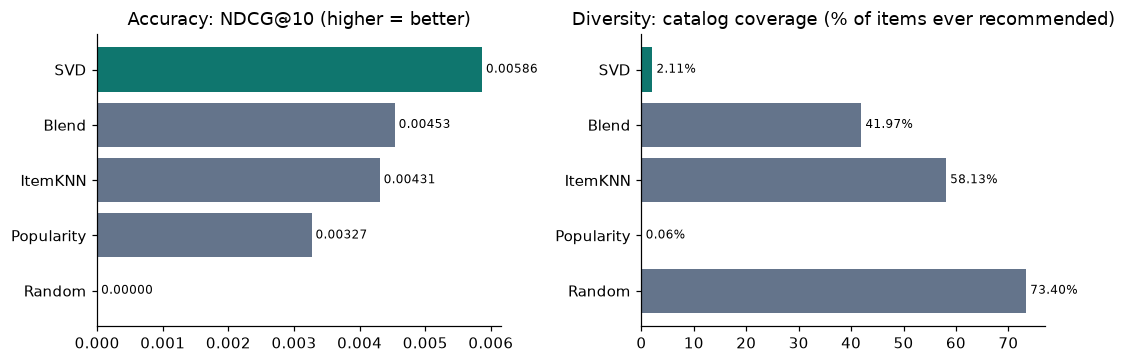

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
order = results.index.tolist()
colors = ['#0f766e' if m == order[0] else '#64748b' for m in order]

axes[0].barh(order[::-1], results.ndcg_at_10[::-1], color=colors[::-1])
axes[0].set_title('Accuracy: NDCG@10 (higher = better)')
for y, v in enumerate(results.ndcg_at_10[::-1]):
    axes[0].text(v, y, f' {v:.5f}', va='center', fontsize=8)

axes[1].barh(order[::-1], results.catalog_coverage[::-1] * 100, color=colors[::-1])
axes[1].set_title('Diversity: catalog coverage (% of items ever recommended)')
for y, v in enumerate(results.catalog_coverage[::-1] * 100):
    axes[1].text(v, y, f' {v:.2f}%', va='center', fontsize=8)
plt.tight_layout(); plt.show()

**Reading the two panels together**

* **SVD is the most accurate**, yet it recommends only ~2% of the catalog. It leans toward a small set of broadly relevant items.
* **ItemKNN** is a little less accurate but covers ~58% of the catalog. It recommends a much wider variety of products.
* **Popularity** is the same 10 items for everyone, so coverage is ~0.06% (about 13 items across 3,000 users). Yet it beats Random, which says that popularity itself carries signal.
* **Random** has the highest coverage (73%) and *zero* accuracy. Coverage alone is not quality.

### Sanity check: is Random's score of exactly 0 believable?
Pure chance should hit very rarely. The expected number of hits for a random list is about `Σ over users of 10 × (relevant items) / catalog size`:

In [24]:
expected_random_hits = sum(10 * len(test_truth[u]) / len(items) for u in test_users)
observed_random_hits = per_user[per_user.model == 'Random'].precision_at_10.sum() * K
print(f'expected random hits over {len(test_users):,} users: ~{expected_random_hits:.1f}')
print(f'observed random hits                       : {observed_random_hits:.0f}')

expected random hits over 3,000 users: ~2.1
observed random hits                       : 0


About two hits were expected in total across all users, so seeing zero is plausible (roughly a 1-in-8 chance). It also shows how rare a hit is by pure chance: even the best model's 0.0016 precision is far above that floor.

## Step 11 — Is the Blend really better than Popularity? (bootstrap)

The averages differ, but with only 3,000 users and rare hits, part of any gap could be luck. We test the question that was fixed in advance: *does Blend beat Popularity on NDCG@10?*

**Method (paired bootstrap):**
1. For each test user, compute `difference = NDCG(Blend) − NDCG(Popularity)`.
2. Resample the 3,000 differences *with replacement* (same size) and take the mean. Repeat 2,000 times.
3. The 2.5th and 97.5th percentiles of those means form the **95% confidence interval**.

mean difference (Blend - Popularity): +0.00127
95% CI: [-0.00027, +0.00284]
excludes zero? False


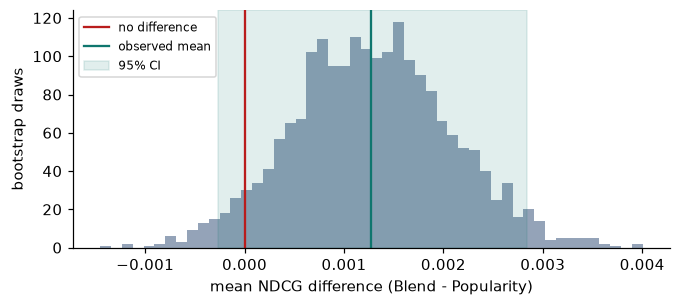

In [25]:
paired = per_user.pivot(index='user_index', columns='model', values='ndcg_at_10')
delta = (paired.Blend - paired.Popularity).to_numpy()          # one difference per user

rng = np.random.default_rng(SEED)
boot_means = [float(rng.choice(delta, len(delta), replace=True).mean()) for _ in range(2000)]
low, high = np.quantile(boot_means, [0.025, 0.975])

print(f'mean difference (Blend - Popularity): {delta.mean():+.5f}')
print(f'95% CI: [{low:+.5f}, {high:+.5f}]')
print('excludes zero?', not (low <= 0 <= high))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(boot_means, bins=50, color='#94a3b8')
ax.axvline(0, color='#b91c1c', label='no difference')
ax.axvline(delta.mean(), color='#0f766e', label='observed mean')
ax.axvspan(low, high, color='#0f766e', alpha=0.12, label='95% CI')
ax.set_xlabel('mean NDCG difference (Blend - Popularity)'); ax.set_ylabel('bootstrap draws'); ax.legend(fontsize=8)
plt.show()

The interval **includes 0**, so on this pilot we **cannot claim** the Blend is genuinely better than Popularity. The point estimate is positive but within the noise. (Different from "no difference exists": the pilot is simply too small to tell.)

## Step 12 — Does this notebook reproduce the saved results?

Compare against the files written by `scripts/benchmark.py`. Fit times differ run to run, so only the metrics are compared.

In [26]:
saved = pd.read_csv(ROOT / 'results/metrics.csv', index_col='model')
cols = ['precision_at_10', 'recall_at_10', 'ndcg_at_10', 'mrr_at_10', 'catalog_coverage']
diff = (results[cols] - saved.loc[results.index, cols]).abs()
print('largest absolute difference vs results/metrics.csv:', f'{diff.to_numpy().max():.2e}')

saved_run = json.loads((ROOT / 'results/run.json').read_text())
print('selected weight matches :', saved_run['selected_knn_weight'] == best_w)
print('bootstrap CI (saved)    :', [round(v, 5) for v in saved_run['blend_minus_popularity_ndcg_paired_bootstrap_95_ci']])
print('bootstrap CI (this run) :', [round(float(low), 5), round(float(high), 5)])

largest absolute difference vs results/metrics.csv: 0.00e+00
selected weight matches : True
bootstrap CI (saved)    : [-0.00027, 0.00284]
bootstrap CI (this run) : [-0.00027, 0.00284]


## What can and cannot be concluded

**Supported by this experiment**
* On this temporal split, collaborative models (SVD, ItemKNN, Blend) all beat Random and Popularity on NDCG@10.
* There is a clear **accuracy ↔ diversity trade-off**: SVD is the most accurate but narrow, ItemKNN is broader.

**Not supported**
* "SVD is the best recommender." This is one split, one sampled test set, untuned hyperparameters, and a stronger model class (ALS, BPR, neural) was not tried.
* "The Blend beats Popularity": the 95% CI includes zero.
* "This would increase sales." Offline ranking against past reviews is not a live experiment, and a review is not a purchase.
* Anything about **new users or new products** (excluded by design) or **images/text** (not used).
* Direct comparison with published numbers that use other splits or *sampled negatives* (ranking against 100 random items instead of the full 22k catalog gives much larger numbers).

**Next steps (from the README)**
1. Add ALS / BPR and tune factors and neighbours on validation data.
2. Add product text and categories (content features) and test a content + collaborative hybrid.
3. Evaluate all eligible users and several time cut-offs, and report uncertainty.
4. Handle cold-start users and items separately.
5. Build a demo UI with product names and images.